# TP 3 : Classification ascendante hiérarchique (CAH) et DBSCAN

**Ressource :** R3.13 - Maintenance Prédictive & Data Science  
**Séance 3 :** Familles de machines et détection du bruit  
**Auteur :** Étudiant en informatique / Data Science  
**Graine aléatoire :** seed = 42

---

## Objectifs du TP

Dans les TP 1 et 2, j'ai préparé les données puis identifié les 4 régimes de marche de l'atelier avec K-means.  
Dans ce troisième TP, j'explore deux méthodes complémentaires :
1. **La CAH (Classification Ascendante Hiérarchique) :** pour regrouper les machines en familles homogènes et analyser l'impact du critère de liaison (effet de chaîne vs critère de Ward).
2. **DBSCAN :** pour isoler les points aberrants ou rares sous forme de bruit sans imposer le nombre de groupes, et analyser la relation entre ces points de bruit et les pannes réelles.
3. **Comparaison sur formes synthétiques 2D :** pour observer visuellement le comportement de K-means, de la CAH (Ward et Single) et de DBSCAN sur des géométries sphériques ou non convexes.


## 0. Environnement et préparation des données

J'importe les bibliothèques utiles et je charge le fichier `atelier_connecte.csv`.  
Comme pour les TP précédents :
- Je retiens les 4 mesures physiques de procédé : `temperature`, `vibration`, `courant`, `cadence`.
- J'impute les valeurs manquantes par la médiane et je standardise avec `StandardScaler()`.
- Je conserve `machine_id`, `regime_reference` et `defaut` uniquement pour analyser les résultats a posteriori.


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors
from sklearn.cluster import DBSCAN, KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.datasets import make_blobs, make_moons, make_circles

from scipy.cluster.hierarchy import linkage, dendrogram, fcluster

SEED = 42
np.random.seed(SEED)

pd.set_option("display.max_columns", 25)
pd.set_option("display.float_format", lambda x: f"{x:.2f}")


In [2]:
data_path = Path("../data/atelier_connecte.csv")
if not data_path.exists():
    data_path = Path("data/atelier_connecte.csv")

df = pd.read_csv(data_path)
print(f"Dataset charge : {df.shape[0]} lignes et {df.shape[1]} colonnes")

mesures = ["temperature", "vibration", "courant", "cadence"]

# Imputation et standardisation
imputer = SimpleImputer(strategy="median")
X_raw = imputer.fit_transform(df[mesures])

scaler = StandardScaler()
X_std = scaler.fit_transform(X_raw)

print(f"Matrice standardisee X_std : {X_std.shape}")


Dataset charge : 1728 lignes et 20 colonnes
Matrice standardisee X_std : (1728, 4)


---
## 1. Familles de machines (CAH avec la méthode de Ward)

Pour comparer les machines de l'atelier, je calcule la moyenne de chaque équipement (M-01 à M-06) sur les 4 capteurs. Je standardise ces 6 profils et j'applique une CAH avec le critère de Ward (`linkage(..., method="ward")`).


In [3]:
profils_machines = df.groupby("machine_id")[mesures].mean()
print("Profils moyens bruts par machine :")
profils_machines.round(2)


Profils moyens bruts par machine :


,temperature,vibration,courant,cadence
machine_id,,,,
M-01,70.49,1.70,11.36,57.43
M-02,73.44,1.97,12.55,54.28
M-03,79.27,3.18,15.44,47.36
M-04,81.32,3.44,16.20,44.51
M-05,75.22,2.38,13.41,51.29
M-06,85.83,4.51,18.10,40.37


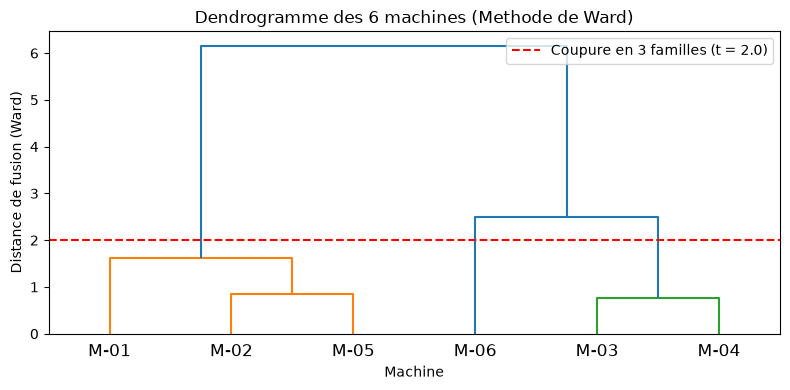

In [4]:
scaler_prof = StandardScaler()
X_prof_std = scaler_prof.fit_transform(profils_machines)

Z_machines = linkage(X_prof_std, method="ward")

plt.figure(figsize=(8, 4))
dendrogram(Z_machines, labels=profils_machines.index.to_list(), color_threshold=2.0)
plt.title("Dendrogramme des 6 machines (Methode de Ward)")
plt.xlabel("Machine")
plt.ylabel("Distance de fusion (Ward)")
plt.axhline(2.0, color="red", linestyle="--", label="Coupure en 3 familles (t = 2.0)")
plt.legend()
plt.tight_layout()
plt.show()


In [5]:
# Decoupage en 3 familles
familles = fcluster(Z_machines, t=3, criterion="maxclust")
profils_machines["Famille"] = familles

bilan_familles = profils_machines.groupby("Famille")[mesures].mean()
bilan_familles["Machines"] = [
    ", ".join(profils_machines.index[profils_machines["Famille"] == f]) 
    for f in bilan_familles.index
]

print("Profils moyens des 3 familles de machines :")
bilan_familles[["Machines"] + mesures].round(2)


Profils moyens des 3 familles de machines :


,Machines,temperature,vibration,courant,cadence
Famille,,,,,
1,"M-01, M-02, M-05",73.05,2.02,12.44,54.33
2,"M-03, M-04",80.30,3.31,15.82,45.94
3,M-06,85.83,4.51,18.10,40.37


### Analyse des 3 familles et du dendrogramme

1. **Les 3 familles identifiées :**
   - **Famille {M-01, M-02, M-05} :** machines à charge modérée. Température basse (~70-75 °C), vibration faible (< 2.4 mm/s), courant réduit (< 13.5 A) et cadence élevée (> 51 pièces/min).
   - **Famille {M-03, M-04} :** machines à charge plus soutenue. Température autour de 80 °C, vibration d'environ 3.2 mm/s et cadence ralentie (~45 pièces/min).
   - **Famille {M-06} :** machine complètement isolée. Sa température atteint 85.8 °C et sa vibration moyenne culmine à 4.51 mm/s (au-delà du seuil critique de 4.2 mm/s).
2. **Ce que montrent les hauteurs de fusion :**
   - Les machines saines fusionnent très tôt (hauteur inférieure à 1.0).
   - La dernière fusion se produit à une hauteur très élevée (6.16) pour raccrocher M-06 au reste du parc, ce qui confirme que M-06 a un comportement totalement atypique nécessitant une maintenance prioritaire.


---
## 2. Comparaison des critères de liaison sur un échantillon

Calculer la CAH sur les 1 728 lignes demande une matrice de distance complète qui peut être lourde. Conformément à l'exercice du cours, je tire un échantillon aléatoire de 300 relevés (`seed = 42`) pour tester 4 critères de liaison :
- Lien simple (`single`) : distance minimale entre points.
- Lien complet (`complete`) : distance maximale.
- Lien moyen (`average`) : distance moyenne entre toutes les paires.
- Lien de Ward (`ward`) : minimisation de l'inertie intra-classe.

Pour chacun, je coupe à t = 4 groupes et je regarde les effectifs, la silhouette et l'indice de Rand ajusté (ARI) par rapport à Ward.


In [6]:
X_ech_df = df[mesures].fillna(df[mesures].median()).sample(300, random_state=SEED)
X_ech = StandardScaler().fit_transform(X_ech_df)

Z_ward_ech = linkage(X_ech, method="ward")
labels_ward = fcluster(Z_ward_ech, t=4, criterion="maxclust")

criteres = ["single", "complete", "average", "ward"]
resultats_liaisons = []

for crit in criteres:
    Z = linkage(X_ech, method=crit)
    labels = fcluster(Z, t=4, criterion="maxclust")
    counts = pd.Series(labels).value_counts().sort_values(ascending=False).tolist()
    sil = silhouette_score(X_ech, labels) if len(set(labels)) > 1 else -1.0
    ari = adjusted_rand_score(labels_ward, labels)
    resultats_liaisons.append({
        "Liaison": crit,
        "Effectifs des 4 groupes": str(counts),
        "Silhouette": sil,
        "ARI vs Ward": ari
    })

pd.DataFrame(resultats_liaisons)


,Liaison,Effectifs des 4 groupes,Silhouette,ARI vs Ward
0,single,"[295, 2, 2, 1]",0.16,0.00
1,complete,"[121, 92, 79, 8]",0.30,0.49
2,average,"[135, 102, 61, 2]",0.39,0.67
3,ward,"[96, 90, 65, 49]",0.31,1.00


### L'effet de chaîne du lien simple vs l'équilibre de Ward

- **Lien simple (`single`) :** Les effectifs obtenus sont `[295, 2, 2, 1]` et l'accord avec Ward est nul (ARI = 0.001). C'est le phénomène typique d'effet de chaîne : dès que deux points sont proches, le lien simple relie les groupes voisins de proche en proche. On se retrouve avec un groupe unique géant de 295 points et trois isolats. Ce critère est inexploitable ici.
- **Méthode de Ward (`ward`) :** Elle donne des effectifs très équilibrés `[96, 90, 65, 49]` en cherchant des groupes compacts à faible variance, ce qui correspond bien à des régimes de marche distincts.


---
## 3. Lecture de la coupure sur le dendrogramme

Je trace le dendrogramme de l'échantillon avec l'option `truncate_mode="lastp"` (p = 20) pour garder un tracé lisible.


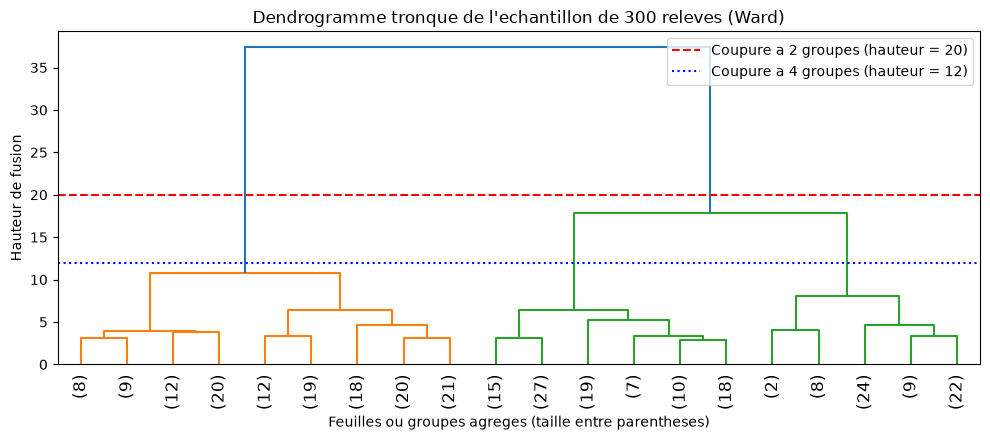

In [7]:
plt.figure(figsize=(10, 4.5))
dendrogram(Z_ward_ech, truncate_mode="lastp", p=20, leaf_rotation=90.0, color_threshold=20.0)
plt.title("Dendrogramme tronque de l'echantillon de 300 releves (Ward)")
plt.xlabel("Feuilles ou groupes agreges (taille entre parentheses)")
plt.ylabel("Hauteur de fusion")
plt.axhline(20.0, color="red", linestyle="--", label="Coupure a 2 groupes (hauteur = 20)")
plt.axhline(12.0, color="blue", linestyle=":", label="Coupure a 4 groupes (hauteur = 12)")
plt.legend()
plt.tight_layout()
plt.show()


In [8]:
top_hauteurs = Z_ward_ech[-5:, 2]
sauts = np.diff(top_hauteurs)

df_sauts = pd.DataFrame({
    "Fusion": [f"Etape {i+1}" for i in range(len(top_hauteurs))],
    "Hauteur": top_hauteurs,
    "Saut vertical": [np.nan] + list(sauts)
})
df_sauts.round(2)


,Fusion,Hauteur,Saut vertical
0,Etape 1,6.41,NaN
1,Etape 2,8.10,1.69
2,Etape 3,10.72,2.62
3,Etape 4,17.89,7.17
4,Etape 5,37.40,19.51


### Quelle coupure choisir ?

1. **Lecture géométrique :** Le plus grand saut vertical se situe entre la hauteur 17.89 et la hauteur 37.40 (+19.51). D'un point de vue purement mathématique, cela suggère de couper en 2 grands groupes.
2. **Besoin métier :** Pour l'équipe de maintenance, couper en 2 groupes est insuffisant : cela mettrait dans un même lot la marche normale et les pannes critiques. Couper plus bas (vers la hauteur 12.0) pour obtenir 4 groupes permet d'isoler les dérives sévères, ce qui est beaucoup plus utile sur le terrain.


---
## 4. Choix du rayon epsilon pour DBSCAN

DBSCAN regroupe les points denses et classe les points isolés en bruit (-1). Il a besoin de deux paramètres :
- `min_samples` : nombre minimal de voisins (fixé à 5 car nous avons 4 variables, règle d + 1).
- `eps` : rayon de voisinage.

Pour trouver une valeur de `eps` adaptée, je calcule la distance au 5e plus proche voisin pour chaque observation avec `NearestNeighbors`.


In [9]:
nn = NearestNeighbors(n_neighbors=5)
nn.fit(X_std)
distances, _ = nn.kneighbors(X_std)

k_distances = np.sort(distances[:, 4])
quantiles = [0.90, 0.95, 0.99]
vals_q = np.quantile(k_distances, quantiles)

for q, v in zip(quantiles, vals_q):
    print(f"Quantile {int(q*100)} % de la 5-distance : {v:.2f}")


Quantile 90 % de la 5-distance : 0.52
Quantile 95 % de la 5-distance : 0.60
Quantile 99 % de la 5-distance : 0.83


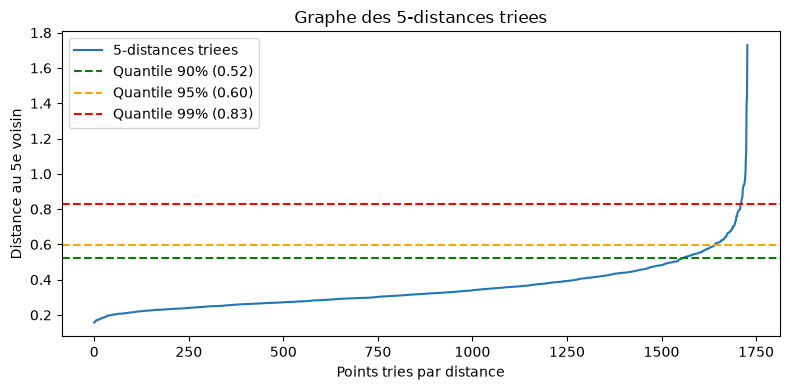

In [10]:
plt.figure(figsize=(8, 4))
plt.plot(k_distances, color="#1f77b4", label="5-distances triees")
plt.axhline(vals_q[0], color="green", linestyle="--", label=f"Quantile 90% ({vals_q[0]:.2f})")
plt.axhline(vals_q[1], color="orange", linestyle="--", label=f"Quantile 95% ({vals_q[1]:.2f})")
plt.axhline(vals_q[2], color="red", linestyle="--", label=f"Quantile 99% ({vals_q[2]:.2f})")

plt.title("Graphe des 5-distances triees")
plt.xlabel("Points tries par distance")
plt.ylabel("Distance au 5e voisin")
plt.legend()
plt.tight_layout()
plt.show()


In [11]:
eps_liste = [0.3, 0.4, 0.5, 0.6, 0.8]
sensibilite = []

for e in eps_liste:
    db = DBSCAN(eps=e, min_samples=5).fit(X_std)
    labels = db.labels_
    nb_clusters = len(set(labels) - {-1})
    bruit_pct = np.mean(labels == -1) * 100
    
    sensibilite.append({
        "eps": e,
        "Clusters hors bruit": nb_clusters,
        "Part de bruit (%)": round(bruit_pct, 1)
    })

pd.DataFrame(sensibilite)


,eps,Clusters hors bruit,Part de bruit (%)
0,0.30,13,38.80
1,0.40,3,14.50
2,0.50,4,4.70
3,0.60,2,1.70
4,0.80,1,0.20


### Choix de epsilon

- Sur le graphique, la courbe s'infléchit nettement entre 0.50 et 0.60 avant de monter très vite vers les valeurs extrêmes.
- Pour `eps = 0.3`, le filtre est trop sévère : 38.8 % des relevés sont rejetés en bruit.
- Pour `eps = 0.6` et `0.8`, le rayon est trop large et avale presque tout le bruit (moins de 2 %).
- `eps = 0.5` se situe au niveau du coude : il garde un groupe principal compact et isole 4.7 % de points en bruit (environ 80 points atypiques).


---
## 5. Analyse du bruit pour epsilon = 0.5

J'entraîne DBSCAN avec `eps = 0.5` et `min_samples = 5`, puis j'étudie les points classés en bruit (`-1`).


In [12]:
db5 = DBSCAN(eps=0.5, min_samples=5).fit(X_std)

df_db = df.copy()
df_db["bruit"] = (db5.labels_ == -1)

taux_defaut_bruit = df_db.loc[df_db["bruit"], "defaut"].mean() * 100
taux_defaut_dense = df_db.loc[~df_db["bruit"], "defaut"].mean() * 100

print(f"Nombre total de points en bruit : {df_db['bruit'].sum()} ({df_db['bruit'].mean()*100:.1f} %)")
print(f"Taux de defaut dans le bruit : {taux_defaut_bruit:.1f} %")
print(f"Taux de defaut hors bruit   : {taux_defaut_dense:.1f} %")
print(f"Sur-risque dans le bruit    : x{taux_defaut_bruit / taux_defaut_dense:.1f}")


Nombre total de points en bruit : 81 (4.7 %)
Taux de defaut dans le bruit : 42.0 %
Taux de defaut hors bruit   : 7.9 %
Sur-risque dans le bruit    : x5.3


In [13]:
bruit_par_machine = pd.crosstab(df_db["machine_id"], df_db["bruit"], normalize="index") * 100
bruit_par_machine.columns = ["Hors bruit (%)", "En bruit (%)"]
bruit_par_machine.round(1)


,Hors bruit (%),En bruit (%)
machine_id,,
M-01,95.80,4.20
M-02,97.20,2.80
M-03,96.50,3.50
M-04,94.80,5.20
M-05,97.60,2.40
M-06,89.90,10.10


In [14]:
bruit_par_regime = pd.crosstab(df_db["regime_reference"], df_db["bruit"], normalize="index") * 100
bruit_par_regime.columns = ["Hors bruit (%)", "En bruit (%)"]
bruit_par_regime.round(1)


,Hors bruit (%),En bruit (%)
regime_reference,,
charge_elevee,99.00,1.00
incident_roulement,64.30,35.70
incident_thermique,96.80,3.20
nominal,97.80,2.20
usure_avancee,95.60,4.40


In [15]:
masque_dense = ~df_db["bruit"]
sil_dense = silhouette_score(X_std[masque_dense], db5.labels_[masque_dense])
print(f"Score de silhouette hors bruit : {sil_dense:.3f}")


Score de silhouette hors bruit : 0.027


### Que révèle l'analyse du bruit ?

1. **Lien direct avec les pannes :** Le taux de pièces défectueuses atteint 42.0 % dans les points de bruit, contre seulement 7.9 % dans les zones denses. Les points de bruit ne sont donc pas de simples erreurs de mesure, mais des anomalies réelles de fonctionnement.
2. **Machines et régimes touchés :**
   - M-06 a plus de 10 % de ses relevés classés en bruit, soit quatre fois plus que les machines stables (M-02 à 2.8 %, M-05 à 2.4 %).
   - Le régime d'incident de roulement a 35.7 % de ses points dans le bruit, contre seulement 2.2 % pour le régime nominal.
3. **Pourquoi la silhouette hors bruit est proche de zéro (0.027) ?**
   - L'atelier d'usinage évolue de façon continue sans coupure nette entre les régimes normaux. DBSCAN relie tous les points denses de proche en proche et crée un seul grand cluster continu. DBSCAN n'est donc pas fait pour partitionner ce continuum, mais il est très efficace pour détecter les points anormaux qui s'en écartent.


---
## 6. Comparaison sur formes synthétiques 2D

Pour observer les limites de chaque algorithme, je génère 3 jeux de test en 2D (300 points chacun) :
- Blobs gaussiens (formes rondes convexes).
- Deux croissants / Moons (formes étirées non convexes).
- Cercles concentriques (structure imbriquée).

Je teste K-means, CAH (Ward et Single) et DBSCAN, puis je compare leurs scores ARI.


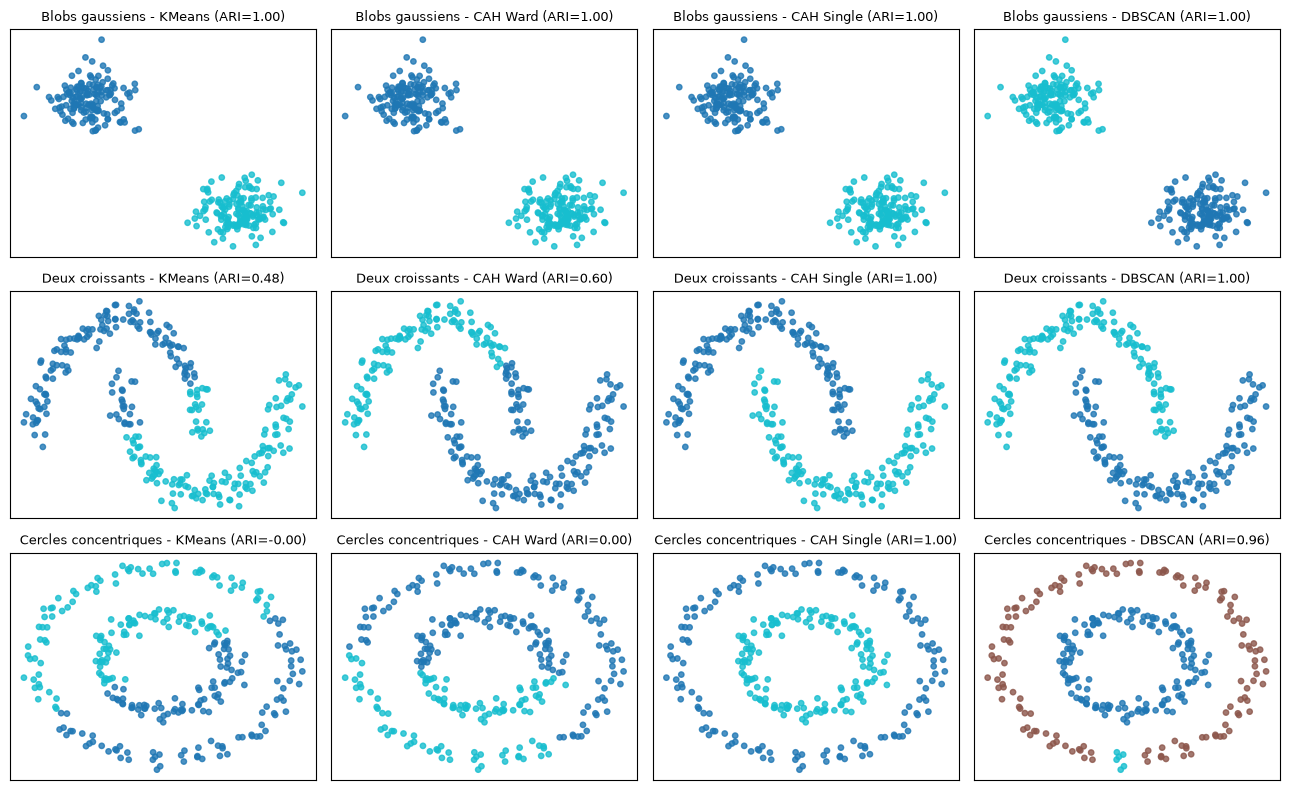

In [16]:
formes = {
    "Blobs gaussiens": make_blobs(n_samples=300, centers=2, cluster_std=1.0, random_state=SEED),
    "Deux croissants": make_moons(n_samples=300, noise=0.07, random_state=SEED),
    "Cercles concentriques": make_circles(n_samples=300, factor=0.5, noise=0.05, random_state=SEED)
}

eps_config = {"Blobs gaussiens": 0.5, "Deux croissants": 0.3, "Cercles concentriques": 0.3}

scores = []
fig, axes = plt.subplots(3, 4, figsize=(13, 8))

for r, (nom, (X_f, y_f)) in enumerate(formes.items()):
    X_f_std = StandardScaler().fit_transform(X_f)
    
    # 1. KMeans
    km = KMeans(n_clusters=2, n_init=20, random_state=SEED).fit(X_f_std)
    ari_km = adjusted_rand_score(y_f, km.labels_)
    
    # 2. CAH Ward
    cah_w = AgglomerativeClustering(n_clusters=2, linkage="ward").fit(X_f_std)
    ari_w = adjusted_rand_score(y_f, cah_w.labels_)
    
    # 3. CAH Single
    cah_s = AgglomerativeClustering(n_clusters=2, linkage="single").fit(X_f_std)
    ari_s = adjusted_rand_score(y_f, cah_s.labels_)
    
    # 4. DBSCAN
    db = DBSCAN(eps=eps_config[nom], min_samples=5).fit(X_f_std)
    ari_db = adjusted_rand_score(y_f, db.labels_)
    
    scores.append({"Forme": nom, "KMeans": ari_km, "CAH Ward": ari_w, "CAH Single": ari_s, "DBSCAN": ari_db})
    
    modeles = [("KMeans", km.labels_, ari_km), ("CAH Ward", cah_w.labels_, ari_w), 
               ("CAH Single", cah_s.labels_, ari_s), ("DBSCAN", db.labels_, ari_db)]
    
    for c, (titre, labs, sc) in enumerate(modeles):
        ax = axes[r, c]
        ax.scatter(X_f_std[:, 0], X_f_std[:, 1], c=labs, cmap="tab10", s=15, alpha=0.8)
        ax.set_title(f"{nom} - {titre} (ARI={sc:.2f})", fontsize=9)
        ax.set_xticks([])
        ax.set_yticks([])

plt.tight_layout()
plt.show()


In [17]:
pd.DataFrame(scores).round(2)


,Forme,KMeans,CAH Ward,CAH Single,DBSCAN
0,Blobs gaussiens,1.00,1.00,1.00,1.00
1,Deux croissants,0.48,0.60,1.00,1.00
2,Cercles concentriques,-0.00,0.00,1.00,0.96


### Analyse des formes synthétiques

- **K-means et CAH Ward :** Ils obtiennent un ARI parfait de 1.00 sur les blobs gaussiens car les groupes sont sphériques. En revanche, ils échouent sur les croissants (ARI ~ 0.48 à 0.60) et totalement sur les cercles concentriques (ARI = 0.00) car ils cherchent des frontières linéaires ou convexes.
- **CAH Single et DBSCAN :** Grâce à leur logique de proximité locale ou de densité, ils retrouvent parfaitement les deux croissants et les deux cercles concentriques (ARI = 1.00).


---
## Synthèse pour le service maintenance

En pratique, DBSCAN est très utile comme système d'alerte : tout point étiqueté en bruit correspond à un comportement rare et présente un risque de défaut multiplié par 5 (42 % de pièces défectueuses dans le bruit contre 8 % dans le reste des données). En revanche, DBSCAN ne convient pas pour découper les régimes de marche de l'atelier, car il réunit toutes les données saines dans un seul bloc continu. La solution la plus efficace consiste donc à combiner K-means (ou la CAH de Ward) pour définir les régimes normaux d'exploitation, et DBSCAN pour déclencher une alerte immédiate dès qu'un relevé passe dans le bruit.
